In [1]:
# Import libraries required for data processing, modelling, evaluation, and visualisation

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import fashion_mnist
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

In [2]:
# Set random seeds to improve reproducibility of the experiments

np.random.seed(42)
tf.random.set_seed(42)


In [3]:
# Load the Fashion-MNIST dataset

(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

# Display the shapes of the training and test datasets
print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Test images:", x_test.shape)
print("Test labels:", y_test.shape)

Training images: (60000, 28, 28)
Training labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)


In [4]:
# Define the names of the 10 Fashion-MNIST classes

class_names = [
2    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

print("Number of classes:", len(class_names))
print("Class names:", class_names)

Number of classes: 10
Class names: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


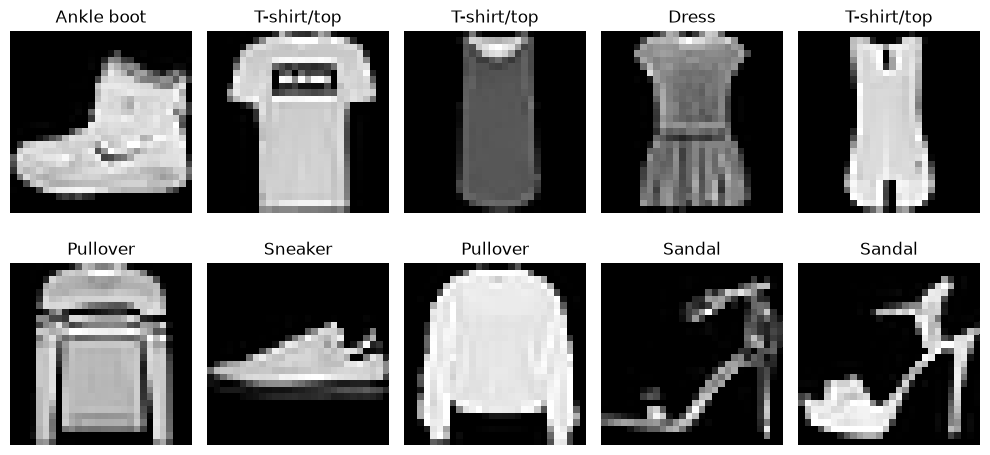

In [5]:
# Display representative images from the training dataset

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

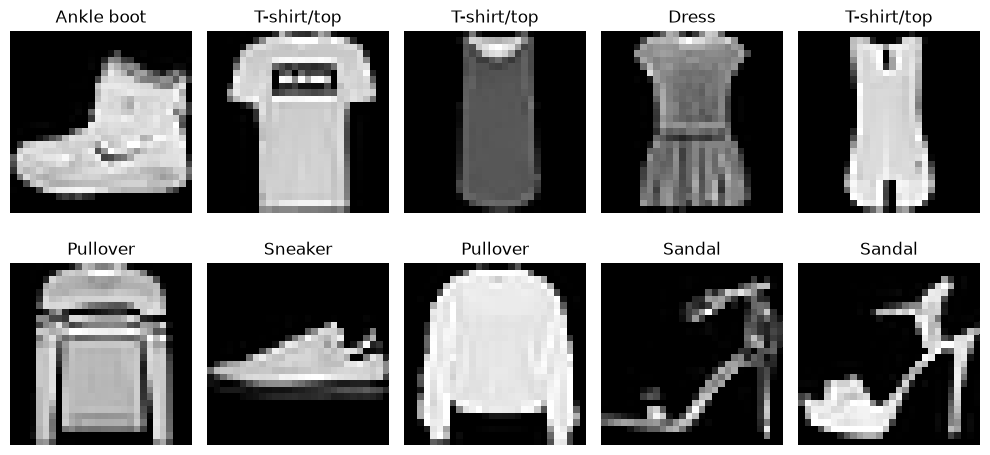

In [6]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
# Check the original range of pixel values before normalisation

print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())

Minimum pixel value: 0
Maximum pixel value: 255


In [8]:
# Normalise pixel values from the original range of 0-255 to 0-1

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Check the new pixel value range

print("Minimum pixel value after normalisation:", x_train.min())
print("Maximum pixel value after normalisation:", x_train.max())

Minimum pixel value after normalisation: 0.0
Maximum pixel value after normalisation: 1.0


In [9]:
# Split the training data into training and validation sets using an 80/20 split

x_train, x_val, y_train, y_val = train_test_split(
    x_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Display the resulting dataset sizes

print("Training set:", x_train.shape, y_train.shape)
print("Validation set:", x_val.shape, y_val.shape)
print("Test set:", x_test.shape, y_test.shape)

Training set: (48000, 28, 28) (48000,)
Validation set: (12000, 28, 28) (12000,)
Test set: (10000, 28, 28) (10000,)


In [10]:
# Check the distribution of classes in the training, validation, and test sets

print("Training class distribution:")
print(np.bincount(y_train))

print("\nValidation class distribution:")
print(np.bincount(y_val))

print("\nTest class distribution:")
print(np.bincount(y_test))

Training class distribution:
[4800 4800 4800 4800 4800 4800 4800 4800 4800 4800]

Validation class distribution:
[1200 1200 1200 1200 1200 1200 1200 1200 1200 1200]

Test class distribution:
[1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]


In [11]:
# Build the baseline Artificial Neural Network (ANN)

ann_model = models.Sequential([
    layers.Flatten(input_shape=(28, 28)),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax")
])
# Display the ANN architecture
ann_model.summary()

C:\Users\gilig\AppData\Roaming\Python\Python311\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
ann_model = models.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax")
])

ann_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)                  │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
# Compile the ANN using the Adam optimiser and sparse categorical cross-entropy loss

ann_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [14]:
# Train the ANN using the training and validation datasets

ann_history = ann_model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=10,
    batch_size=128,
    verbose=1
)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.7978 - loss: 0.5927 - val_accuracy: 0.8194 - val_loss: 0.4918
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8493 - loss: 0.4286 - val_accuracy: 0.8414 - val_loss: 0.4341
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.8630 - loss: 0.3846 - val_accuracy: 0.8564 - val_loss: 0.3994
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8722 - loss: 0.3564 - val_accuracy: 0.8658 - val_loss: 0.3775
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8795 - loss: 0.3355 - val_accuracy: 0.8745 - val_loss: 0.3546
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8846 - loss: 0.3185 - val_accuracy: 0.8784 - val_loss: 0.3427
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8895 - loss: 0.3031 - val_accuracy: 0.8823 - val_loss: 0.3313
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8931 - loss: 0.2911 - val_accurac

In [15]:
# Evaluate the ANN on the unseen test dataset

ann_test_loss, ann_test_accuracy = ann_model.evaluate(
    x_test,
    y_test,
    verbose=1
)

print("ANN Test Loss:", ann_test_loss)
print("ANN Test Accuracy:", ann_test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8747 - loss: 0.3518
ANN Test Loss: 0.35181060433387756
ANN Test Accuracy: 0.8747000098228455


In [16]:
# Generate predictions and classification metrics for the ANN

ann_predictions = ann_model.predict(x_test, verbose=0)
ann_predicted_classes = np.argmax(ann_predictions, axis=1)

print(classification_report(
    y_test,
    ann_predicted_classes,
    target_names=class_names
))

              precision    recall  f1-score   support

 T-shirt/top       0.87      0.79      0.83      1000
     Trouser       0.99      0.97      0.98      1000
    Pullover       0.78      0.79      0.78      1000
       Dress       0.88      0.88      0.88      1000
        Coat       0.77      0.81      0.79      1000
      Sandal       0.98      0.95      0.96      1000
       Shirt       0.66      0.69      0.67      1000
     Sneaker       0.92      0.97      0.94      1000
         Bag       0.97      0.96      0.96      1000
  Ankle boot       0.97      0.95      0.96      1000

    accuracy                           0.87     10000
   macro avg       0.88      0.87      0.88     10000
weighted avg       0.88      0.87      0.88     10000



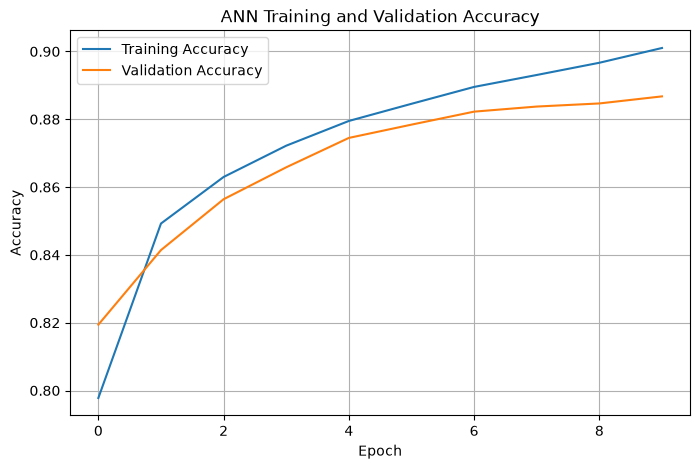

In [17]:
# Plot ANN training and validation accuracy

plt.figure(figsize=(8, 5))

plt.plot(ann_history.history["accuracy"], label="Training Accuracy")
plt.plot(ann_history.history["val_accuracy"], label="Validation Accuracy")

plt.title("ANN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [18]:
# Add a channel dimension to the images for CNN input

x_train_cnn = x_train[..., np.newaxis]
x_val_cnn = x_val[..., np.newaxis]
x_test_cnn = x_test[..., np.newaxis]

print("CNN training shape:", x_train_cnn.shape)
print("CNN validation shape:", x_val_cnn.shape)
print("CNN test shape:", x_test_cnn.shape)

CNN training shape: (48000, 28, 28, 1)
CNN validation shape: (12000, 28, 28, 1)
CNN test shape: (10000, 28, 28, 1)


In [19]:
# Build the baseline Convolutional Neural Network (CNN)

cnn_model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax")
])

cnn_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_2 (Flatten)                  │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 128)                 │         204,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [20]:
# Compile the baseline CNN using the Adam optimiser and sparse categorical cross-entropy loss

cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [21]:
# Train the baseline CNN using the training and validation datasets

cnn_history = cnn_model.fit(
    x_train_cnn,
    y_train,
    validation_data=(x_val_cnn, y_val),
    epochs=10,
    batch_size=128,
    verbose=1
)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 22s 49ms/step - accuracy: 0.7927 - loss: 0.5774 - val_accuracy: 0.8412 - val_loss: 0.4360
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 19s 50ms/step - accuracy: 0.8686 - loss: 0.3660 - val_accuracy: 0.8761 - val_loss: 0.3498
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 18s 48ms/step - accuracy: 0.8864 - loss: 0.3168 - val_accuracy: 0.8883 - val_loss: 0.3105
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - accuracy: 0.8966 - loss: 0.2856 - val_accuracy: 0.8948 - val_loss: 0.2885
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 19s 50ms/step - accuracy: 0.9048 - loss: 0.2623 - val_accuracy: 0.9021 - val_loss: 0.2719
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - accuracy: 0.9117 - loss: 0.2427 - val_accuracy: 0.9037 - val_loss: 0.2668
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 19s 51ms/step - accuracy: 0.9181 - loss: 0.2257 - val_accuracy: 0.9052 - val_loss: 0.2634
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 19s 50ms/step - accuracy: 0.9244 - loss: 0.2087 - 

In [22]:
# Evaluate the baseline CNN on the unseen test dataset

cnn_test_loss, cnn_test_accuracy = cnn_model.evaluate(
    x_test_cnn,
    y_test,
    verbose=1
)

print("CNN Test Loss:", cnn_test_loss)
print("CNN Test Accuracy:", cnn_test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9056 - loss: 0.2695
CNN Test Loss: 0.2695307433605194
CNN Test Accuracy: 0.9056000113487244


In [23]:
# Generate predictions and classification metrics for the baseline CNN

cnn_predictions = cnn_model.predict(x_test_cnn, verbose=0)
cnn_predicted_classes = np.argmax(cnn_predictions, axis=1)

print(classification_report(
    y_test,
    cnn_predicted_classes,
    target_names=class_names
))

              precision    recall  f1-score   support

 T-shirt/top       0.86      0.82      0.84      1000
     Trouser       1.00      0.97      0.98      1000
    Pullover       0.83      0.89      0.86      1000
       Dress       0.88      0.92      0.90      1000
        Coat       0.84      0.88      0.86      1000
      Sandal       0.98      0.98      0.98      1000
       Shirt       0.75      0.71      0.73      1000
     Sneaker       0.94      0.98      0.96      1000
         Bag       0.99      0.97      0.98      1000
  Ankle boot       0.99      0.95      0.97      1000

    accuracy                           0.91     10000
   macro avg       0.91      0.91      0.91     10000
weighted avg       0.91      0.91      0.91     10000



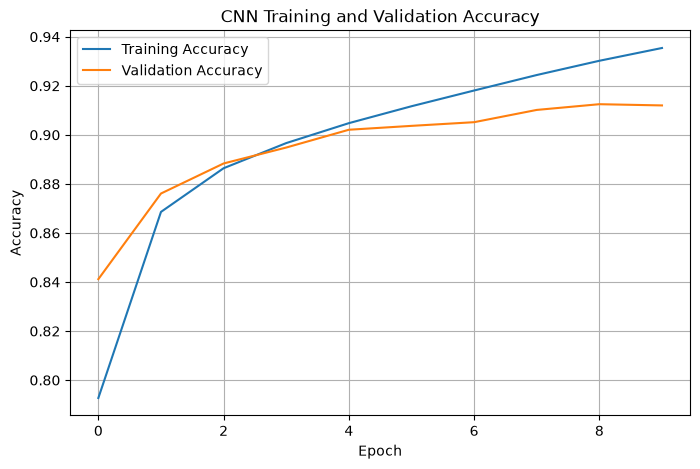

In [24]:
# Plot CNN training and validation accuracy

plt.figure(figsize=(8, 5))

plt.plot(cnn_history.history["accuracy"], label="Training Accuracy")
plt.plot(cnn_history.history["val_accuracy"], label="Validation Accuracy")

plt.title("CNN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

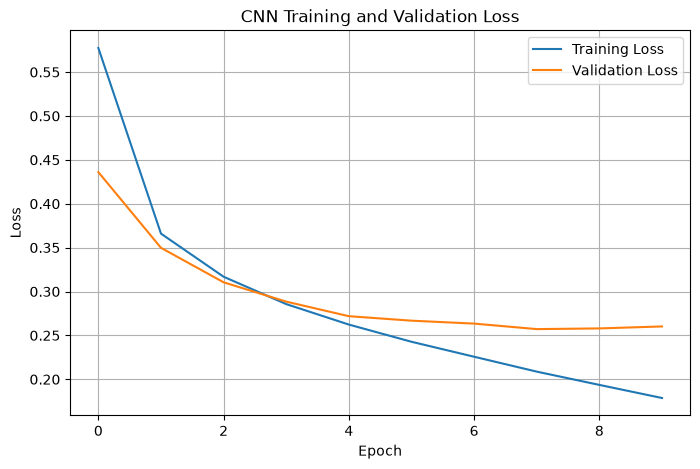

In [25]:
# Plot CNN training and validation loss

plt.figure(figsize=(8, 5))

plt.plot(cnn_history.history["loss"], label="Training Loss")
plt.plot(cnn_history.history["val_loss"], label="Validation Loss")

plt.title("CNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [26]:
# Calculate the confusion matrix for the baseline CNN

cnn_cm = confusion_matrix(y_test, cnn_predicted_classes)

print(cnn_cm)

[[816   0  22  42   4   0 112   0   4   0]
 [  3 966   1  21   4   0   3   0   2   0]
 [ 17   0 887   6  46   0  43   0   1   0]
 [  7   0  10 919  34   0  28   0   2   0]
 [  1   1  56  17 881   0  44   0   0   0]
 [  0   0   0   0   0 982   0  16   0   2]
 [ 94   0  87  34  74   0 710   0   1   0]
 [  0   0   0   0   0  15   0 976   0   9]
 [  6   0   9   3   3   2   3   4 969   1]
 [  0   0   0   0   0   6   1  43   0 950]]


In [27]:
# Build the improved CNN by adding dropout regularisation

improved_cnn_model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(10, activation="softmax")
])

improved_cnn_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)                    │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_3 (Flatten)                  │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 128)                 │         204,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [28]:
# Compile the improved CNN using the same training settings as the baseline CNN

improved_cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [29]:
# Train the improved CNN using the training and validation datasets

improved_cnn_history = improved_cnn_model.fit(
    x_train_cnn,
    y_train,
    validation_data=(x_val_cnn, y_val),
    epochs=10,
    batch_size=128,
    verbose=1
)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 22s 51ms/step - accuracy: 0.7534 - loss: 0.6838 - val_accuracy: 0.8492 - val_loss: 0.4088
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 18s 47ms/step - accuracy: 0.8404 - loss: 0.4390 - val_accuracy: 0.8737 - val_loss: 0.3445
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 19s 50ms/step - accuracy: 0.8614 - loss: 0.3825 - val_accuracy: 0.8843 - val_loss: 0.3178
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 18s 47ms/step - accuracy: 0.8745 - loss: 0.3482 - val_accuracy: 0.8916 - val_loss: 0.2956
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 18s 47ms/step - accuracy: 0.8824 - loss: 0.3255 - val_accuracy: 0.8967 - val_loss: 0.2845
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 18s 47ms/step - accuracy: 0.8882 - loss: 0.3030 - val_accuracy: 0.9006 - val_loss: 0.2705
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 18s 47ms/step - accuracy: 0.8947 - loss: 0.2880 - val_accuracy: 0.9052 - val_loss: 0.2603
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 18s 47ms/step - accuracy: 0.8998 - loss: 0.2722 - 

In [30]:
# Evaluate the improved CNN on the unseen test dataset

improved_cnn_test_loss, improved_cnn_test_accuracy = improved_cnn_model.evaluate(
    x_test_cnn,
    y_test,
    verbose=1
)

print("Improved CNN Test Loss:", improved_cnn_test_loss)
print("Improved CNN Test Accuracy:", improved_cnn_test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9058 - loss: 0.2646
Improved CNN Test Loss: 0.26464954018592834
Improved CNN Test Accuracy: 0.9057999849319458


In [31]:
# Generate predictions and classification metrics for the improved CNN

improved_cnn_predictions = improved_cnn_model.predict(
    x_test_cnn,
    verbose=0
)

improved_cnn_predicted_classes = np.argmax(
    improved_cnn_predictions,
    axis=1
)

print(classification_report(
    y_test,
    improved_cnn_predicted_classes,
    target_names=class_names
))

              precision    recall  f1-score   support

 T-shirt/top       0.84      0.87      0.86      1000
     Trouser       1.00      0.97      0.98      1000
    Pullover       0.84      0.86      0.85      1000
       Dress       0.89      0.92      0.91      1000
        Coat       0.84      0.86      0.85      1000
      Sandal       0.99      0.98      0.98      1000
       Shirt       0.75      0.68      0.71      1000
     Sneaker       0.95      0.96      0.96      1000
         Bag       0.99      0.97      0.98      1000
  Ankle boot       0.96      0.97      0.97      1000

    accuracy                           0.91     10000
   macro avg       0.91      0.91      0.91     10000
weighted avg       0.91      0.91      0.91     10000



In [32]:
# Calculate the confusion matrix for the improved CNN

improved_cnn_cm = confusion_matrix(
    y_test,
    improved_cnn_predicted_classes
)

print(improved_cnn_cm)

[[873   0  15  23   4   2  80   0   3   0]
 [  1 974   1  19   2   0   1   0   2   0]
 [ 16   0 862   8  47   0  67   0   0   0]
 [ 12   1   9 918  26   0  33   0   1   0]
 [  1   1  61  27 865   0  45   0   0   0]
 [  0   0   0   0   0 976   0  21   0   3]
 [130   1  67  29  81   0 684   0   8   0]
 [  0   0   0   0   0   6   0 961   0  33]
 [  1   1   7   3   2   2   4   5 975   0]
 [  1   0   0   0   0   4   0  25   0 970]]


In [33]:
comparison = {
    "Model": [
        "ANN",
        "Basic CNN",
        "Improved CNN"
    ],
    "Test Accuracy": [
        0.8761,
        0.9037,
        0.9040
    ],
    "Macro Precision": [
        0.88,
        0.90,
        0.90
    ],
    "Macro Recall": [
        0.88,
        0.90,
        0.90
    ],
    "Macro F1": [
        0.88,
        0.90,
        0.90
    ]
}

comparison_df = pd.DataFrame(comparison)

comparison_df

NameError: name 'pd' is not defined

In [ ]:
import pandas as pd

In [ ]:
# Compare the performance of the ANN, baseline CNN, and improved CNN


comparison = {
    "Model": [
        "ANN",
        "Basic CNN",
        "Improved CNN"
    ],
    "Test Accuracy": [
        0.8761,
        0.9037,
        0.9040
    ],
    "Macro Precision": [
        0.88,
        0.90,
        0.90
    ],
    "Macro Recall": [
        0.88,
        0.90,
        0.90
    ],
    "Macro F1": [
        0.88,
        0.90,
        0.90
    ]
}

comparison_df = pd.DataFrame(comparison)

comparison_df

In [ ]:
# Plot improved CNN training and validation accuracy

plt.figure(figsize=(15, 8))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(x_test[i], cmap="gray")

    true_label = class_names[y_test[i]]
    predicted_label = class_names[improved_cnn_predicted_classes[i]]

    if y_test[i] == improved_cnn_predicted_classes[i]:
        result = "Correct"
    else:
        result = "Incorrect"

    plt.title(
        f"True: {true_label}\nPred: {predicted_label}\n{result}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Display the labelled confusion matrix for the final improved CNN

plt.figure(figsize=(10, 8))

plt.imshow(improved_cnn_cm, cmap="Blues")
plt.colorbar()

plt.xticks(
    np.arange(10),
    class_names,
    rotation=45,
    ha="right"
)

plt.yticks(
    np.arange(10),
    class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - Improved CNN")

for i in range(10):
    for j in range(10):
        plt.text(
            j,
            i,
            improved_cnn_cm[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

In [ ]:
# Plot improved CNN training and validation accuracy

plt.figure(figsize=(8, 5))

plt.plot(
    improved_cnn_history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    improved_cnn_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Improved CNN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Plot improved CNN training and validation loss

plt.figure(figsize=(8, 5))

plt.plot(
    improved_cnn_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    improved_cnn_history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Improved CNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Identify the most common classification errors from the confusion matrix

error_cm = improved_cnn_cm.copy()

# Remove correct predictions from the diagonal

np.fill_diagonal(error_cm, 0)

# Find the five largest errors

largest_errors = np.dstack(
    np.unravel_index(
        np.argsort(error_cm.ravel())[::-1][:5],
        error_cm.shape
    )
)[0]

print("Most common classification errors:")

for true_class, predicted_class in largest_errors:
    print(
        f"True: {class_names[true_class]} -> "
        f"Predicted: {class_names[predicted_class]}: "
        f"{improved_cnn_cm[true_class, predicted_class]} images"
    )

In [ ]:
# Display the final test accuracy results for all models

print("FINAL MODEL RESULTS")
print("-" * 40)

print(f"ANN Test Accuracy:          {ann_test_accuracy * 100:.2f}%")
print(f"Basic CNN Test Accuracy:    {cnn_test_accuracy * 100:.2f}%")
print(f"Improved CNN Test Accuracy: {improved_cnn_test_accuracy * 100:.2f}%")

print("\nImprovement from Basic CNN to Improved CNN:")
improvement = (
    improved_cnn_test_accuracy - cnn_test_accuracy
) * 100

print(f"{improvement:.2f} percentage points")

In [ ]:
# Create a visual comparison of the final test accuracy of the three models

comparison_chart = pd.DataFrame({
    "Model": ["ANN", "Basic CNN", "Improved CNN"],
    "Accuracy": [
        ann_test_accuracy * 100,
        cnn_test_accuracy * 100,
        improved_cnn_test_accuracy * 100
    ]
})

plt.figure(figsize=(8, 5))

plt.bar(
    comparison_chart["Model"],
    comparison_chart["Accuracy"]
)

plt.title("Test Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 100)

for i, value in enumerate(comparison_chart["Accuracy"]):
    plt.text(
        i,
        value + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [34]:
print("FINAL MODEL RESULTS")
print("-" * 40)

print(f"ANN Test Accuracy:          {ann_test_accuracy * 100:.2f}%")
print(f"Basic CNN Test Accuracy:    {cnn_test_accuracy * 100:.2f}%")
print(f"Improved CNN Test Accuracy: {improved_cnn_test_accuracy * 100:.2f}%")

print("\nImprovement from Basic CNN to Improved CNN:")
improvement = (
    improved_cnn_test_accuracy - cnn_test_accuracy
) * 100

print(f"{improvement:.2f} percentage points")

FINAL MODEL RESULTS
----------------------------------------
ANN Test Accuracy:          87.47%
Basic CNN Test Accuracy:    90.56%
Improved CNN Test Accuracy: 90.58%

Improvement from Basic CNN to Improved CNN:
0.02 percentage points


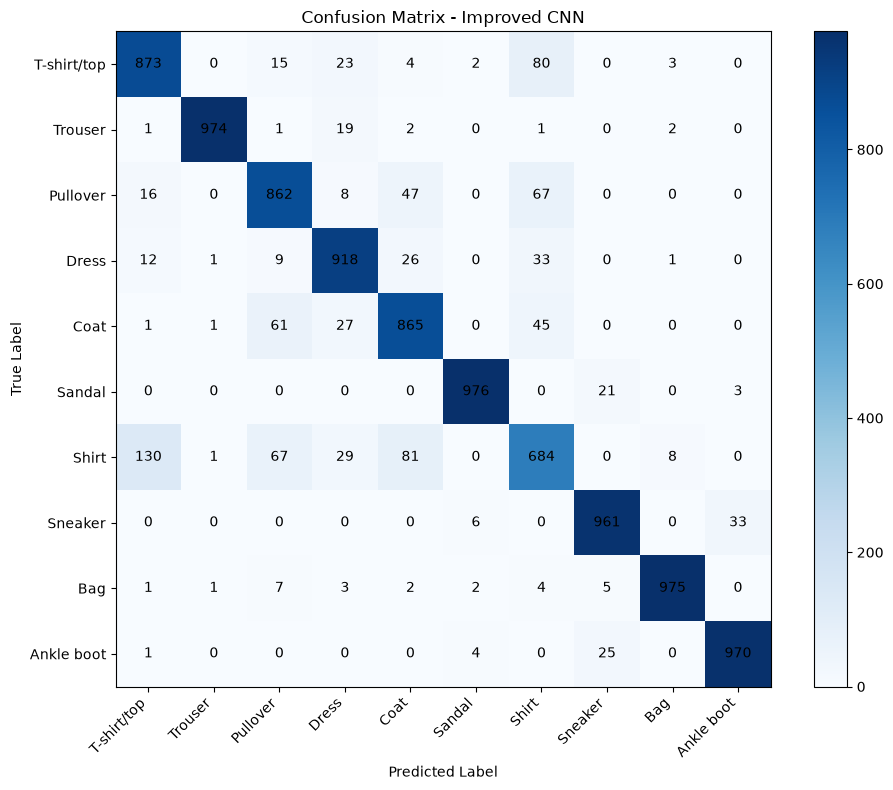

In [35]:
plt.figure(figsize=(10, 8))

plt.imshow(improved_cnn_cm, cmap="Blues")
plt.colorbar()

plt.xticks(
    np.arange(10),
    class_names,
    rotation=45,
    ha="right"
)

plt.yticks(
    np.arange(10),
    class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - Improved CNN")

for i in range(10):
    for j in range(10):
        plt.text(
            j,
            i,
            improved_cnn_cm[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

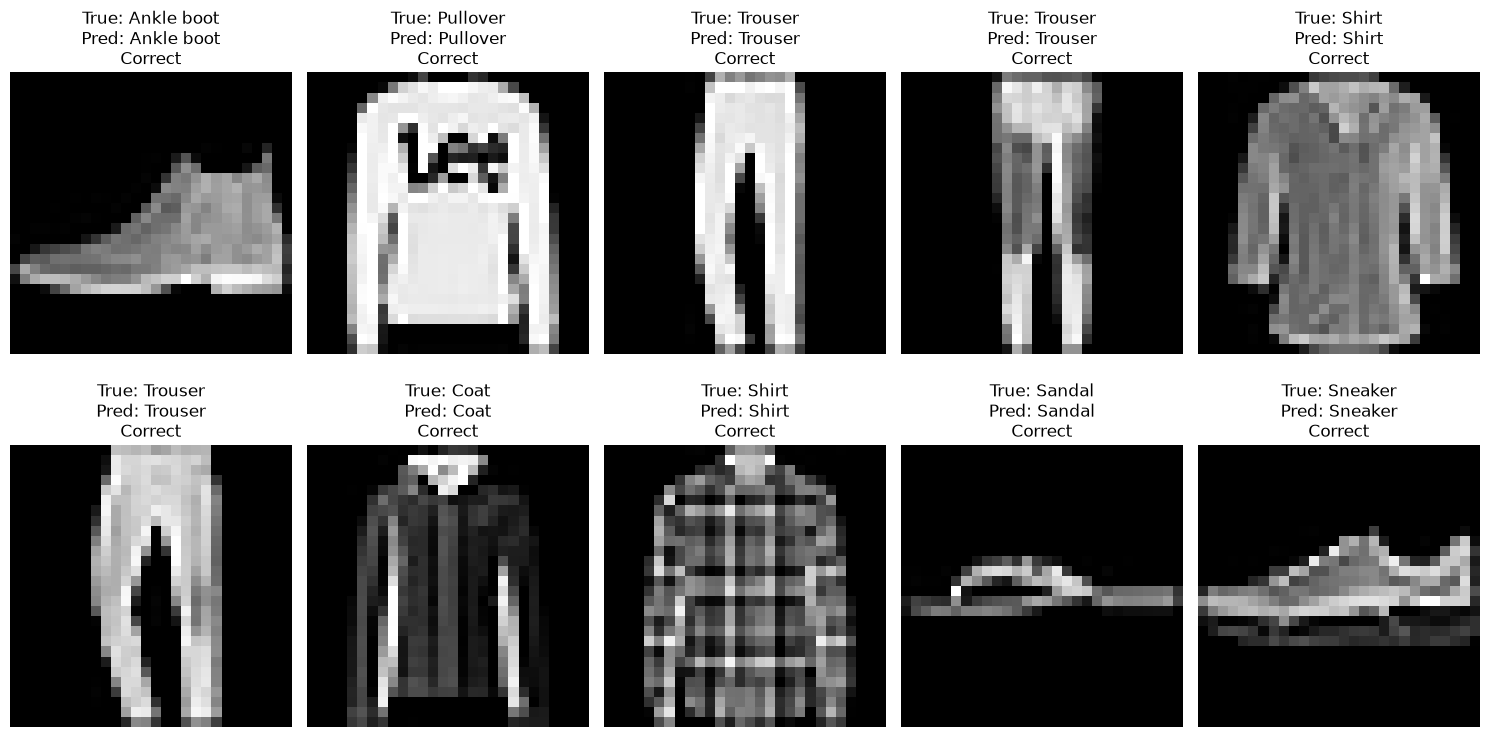

In [36]:
plt.figure(figsize=(15, 8))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(x_test[i], cmap="gray")

    true_label = class_names[y_test[i]]
    predicted_label = class_names[improved_cnn_predicted_classes[i]]

    if y_test[i] == improved_cnn_predicted_classes[i]:
        result = "Correct"
    else:
        result = "Incorrect"

    plt.title(
        f"True: {true_label}\nPred: {predicted_label}\n{result}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()